In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from scipy import stats 
print("all good")

all good


In [2]:
df = pd .read_csv("data/ff.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   game           16 non-null     str    
 1   year           16 non-null     int64  
 2   main           16 non-null     float64
 3   main_side      16 non-null     float64
 4   completionist  16 non-null     float64
 5   metacritic     16 non-null     int64  
 6   type           16 non-null     str    
 7   sales          16 non-null     float64
dtypes: float64(4), int64(2), str(2)
memory usage: 1.1 KB


In [3]:
df.describe()

,year,main,main_side,completionist,metacritic,sales
count,16.00000,16.000000,16.000000,16.00000,16.000000,16.00000
mean,2000.31250,43.718750,73.468750,225.65625,86.187500,8.08750
std,10.35837,28.257134,64.326373,411.22442,5.331901,7.91706
min,1987.00000,16.500000,24.500000,35.00000,77.000000,1.40000
25%,1991.75000,29.125000,40.750000,62.12500,82.750000,3.35000
50%,1999.50000,36.250000,53.750000,82.25000,85.500000,4.80000
75%,2006.75000,41.875000,67.250000,106.00000,92.000000,9.70000
max,2023.00000,120.000000,260.000000,1500.00000,94.000000,30.00000


In [5]:
sp = df[df['type'] == 'SP']
print(len(df), len(sp))

16 14


In [6]:
print("All games - mean:", df["main"].mean(), "median:", df["main"].median())
print("SP games - mean:", sp["main"].mean(), "median:", sp["main"].median())


All games - mean: 43.71875 median: 36.25
SP games - mean: 33.892857142857146 median: 35.5


In [8]:
def summary(data, cols):
    out = {}
    for c in cols:
        x = data[c]
        out[c] = {
            "mean": x.mean(),
            "median": x.median(),
            "mode": x.mode()[0],
            "GM": stats.gmean(x),
            "HM": stats.hmean(x),
            "range": x.max() - x.min(),
            "variance": x.var(),
            "std": x.std(),
            "IQR": x.quantile(0.75) - x.quantile(0.25),
            "CV %": x.std() / x.mean() * 100,
        }
    return pd.DataFrame(out).round(2)

cols = ["main", "main_side", "completionist", "metacritic"]
print("ALL GAMES")
display(summary(df, cols))
print("SINGLE-PLAYER ONLY")
display(summary(sp, cols))

ALL GAMES


,main,main_side,completionist,metacritic
mean,43.72,73.47,225.66,86.19
median,36.25,53.75,82.25,85.50
mode,16.50,54.00,35.00,92.00
GM,38.10,58.41,104.28,86.03
HM,34.34,50.06,76.42,85.88
range,103.50,235.50,1465.00,17.00
variance,798.47,4137.88,169105.52,28.43
std,28.26,64.33,411.22,5.33
IQR,12.75,26.50,43.88,9.25
CV %,64.63,87.56,182.23,6.19


SINGLE-PLAYER ONLY


,main,main_side,completionist,metacritic
mean,33.89,51.11,79.32,86.29
median,35.50,52.75,81.50,86.00
mode,16.50,54.00,35.00,92.00
GM,32.65,48.08,73.34,86.11
HM,31.25,45.05,67.40,85.93
range,32.00,64.50,118.00,17.00
variance,80.85,327.97,1017.56,32.68
std,8.99,18.11,31.90,5.72
IQR,11.25,20.88,39.12,9.75
CV %,26.53,35.44,40.22,6.63


As Final Fantasy XI and XIV are Massively Multiplayer Online Role-Playing Game (MMORPG for short), so we created two separate calculations where one has calculation has all the Final fantasy mainline 16 games and another has removed the MMORPGs. We can see the difference between them both, including the two games result in a mean of 43.72hrs (main); 73.47hrs (main+sides); 225.66hrs(completionist) and a median of 36.25hrs (main); 53.75 (main + sides); 82.25 (completionist).Whereas by removing the two MMORPGs the mean and median drops to 33.89hrs (main); 51.11hrs (main + sides); 79.32hrs (completionist) and 35.50hrs(main); 52.75hrs(main + sides)	81.50hrs (completionist) respectively. so there is a difference of 9.83hrs, 22.36hrs and 146.34hrs in mean respectively and 0.75hrs, 1hrs, 0.75hrs for median respectively. 

In [14]:
hours_per_week = 20
budget = hours_per_week * 52   # 1040 hours in a year

totals = pd.DataFrame({
    "All 16": df[["main", "main_side", "completionist"]].sum(),
    "SP only (14)": sp[["main", "main_side", "completionist"]].sum(),
})
print("Total hours:")
display(totals)
print("Weeks needed at", hours_per_week, "hrs/week:")
display((totals / hours_per_week).round(1))

Total hours:


,All 16,SP only (14)
main,699.5,474.5
main_side,1175.5,715.5
completionist,3610.5,1110.5


Weeks needed at 20 hrs/week:


,All 16,SP only (14)
main,35.0,23.7
main_side,58.8,35.8
completionist,180.5,55.5


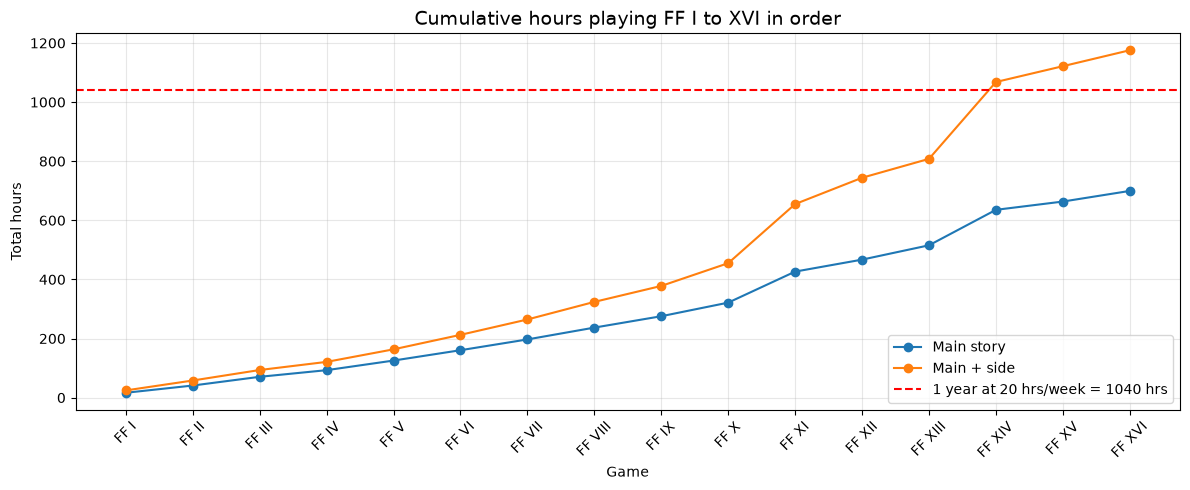

In [15]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df["game"], df["main"].cumsum(), marker="o", label="Main story")
ax.plot(df["game"], df["main_side"].cumsum(), marker="o", label="Main + side")
ax.axhline(budget, color="red", linestyle="--",
           label=f"1 year at {hours_per_week} hrs/week = {budget} hrs")
ax.set_title("Cumulative hours playing FF I to XVI in order", fontsize=14)
ax.set_ylabel("Total hours")
ax.set_xlabel("Game")
plt.xticks(rotation=45)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

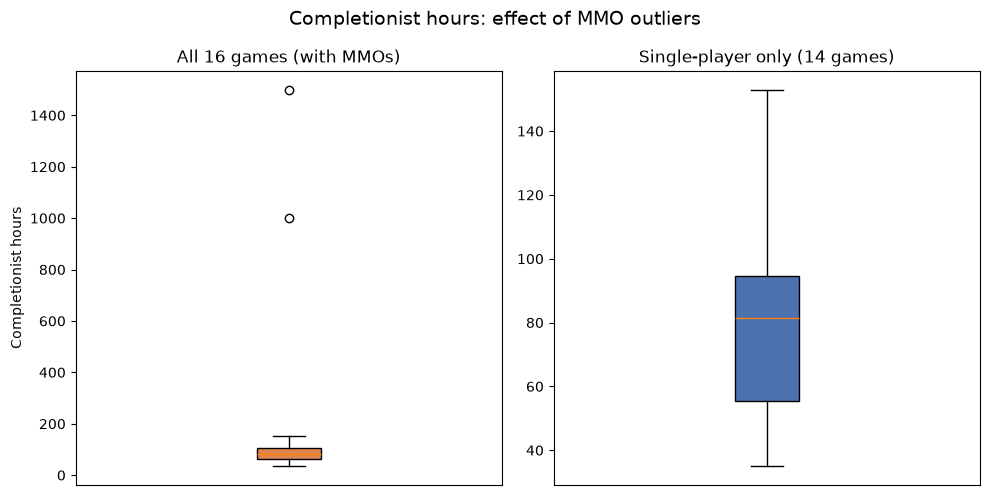

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].boxplot(df["completionist"], patch_artist=True,
                boxprops=dict(facecolor="#DD8452"))
axes[0].set_title("All 16 games (with MMOs)")
axes[0].set_xticks([])
axes[0].set_ylabel("Completionist hours")

axes[1].boxplot(sp["completionist"], patch_artist=True,
                boxprops=dict(facecolor="#4C72B0"))
axes[1].set_title("Single-player only (14 games)")
axes[1].set_xticks([])

fig.suptitle("Completionist hours: effect of MMO outliers", fontsize=14)
plt.tight_layout()
plt.show()

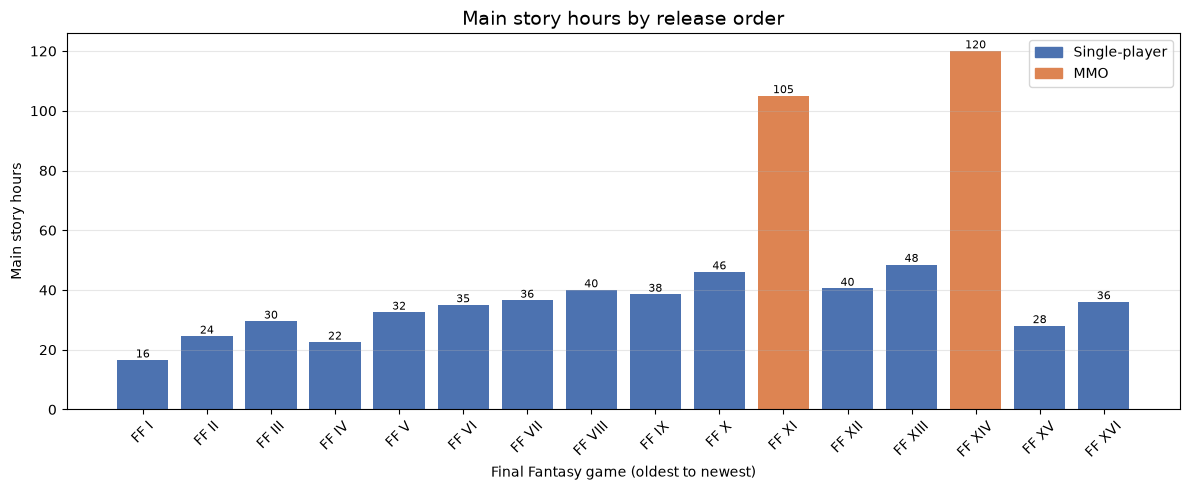

Correlation year vs main (all 16): 0.36
Correlation year vs main (SP only): 0.49


In [12]:
colors = df["type"].map({"SP": "#4C72B0", "MMO": "#DD8452"})

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(df["game"], df["main"], color=colors)
ax.bar_label(bars, fmt="%.0f", fontsize=8)
ax.set_title("Main story hours by release order", fontsize=14)
ax.set_ylabel("Main story hours")
ax.set_xlabel("Final Fantasy game (oldest to newest)")
plt.xticks(rotation=45)

from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#4C72B0", label="Single-player"),
                   Patch(color="#DD8452", label="MMO")])
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Correlation year vs main (all 16):", round(df["year"].corr(df["main"]), 2))
print("Correlation year vs main (SP only):", round(sp["year"].corr(sp["main"]), 2))